# Credit risk prediction: a live walkthrough
**Wilfried Mweneni Nendongo (201304914), BSc Computer Science (Honours), University of Namibia**

This notebook demonstrates the two models built for the mini thesis *A quantitative evaluation of Logistic Regression and Decision Tree models for credit risk prediction using public financial datasets*. It shows, step by step:

1. the data and why imbalance matters;
2. how the saved models are built (the pipeline);
3. that the saved models reproduce the thesis results on the untouched test set;
4. how each model scores a real applicant and *why* it reaches its decision;
5. a what-if experiment, and scoring a batch of applicants.

Run `python train_and_save.py` once before opening this notebook. Then run all cells from the top (Kernel > Restart & Run All).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, RocCurveDisplay, ConfusionMatrixDisplay
from sklearn.tree import plot_tree
import credit_model as cm
pd.set_option("display.width", 140)
models, card = cm.load_models()
print("Models loaded:", list(models))

Models loaded: ['Logistic Regression', 'Decision Tree']


## 1. The data
The Statlog German Credit data hold 1,000 past loan applicants described by 20 attributes. 300 of them (30%) defaulted. **Bad Risk = 1 is the positive class** throughout, because finding defaulters is the lender's main goal.

In [2]:
X, y = cm.load_data()
print(X.shape, "| Bad Risk:", y.sum(), f"({y.mean():.0%})")
X.head()

(1000, 20) | Bad Risk: 300 (30%)


,checking_status,duration,credit_history,purpose,credit_amount,savings,employment,installment_rate,personal_status,other_debtors,residence_since,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker
0,< 0 DM,6,critical account,radio/TV,1169,unknown/none,>= 7 yrs,4,male single,none,4,real estate,67,none,own,2,skilled,1,yes,yes
1,0-200 DM,48,existing paid duly,radio/TV,5951,< 100 DM,1-4 yrs,2,female div/sep/mar,none,2,real estate,22,none,own,1,skilled,1,none,yes
2,no checking account,12,critical account,education,2096,< 100 DM,4-7 yrs,2,male single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes
3,< 0 DM,42,existing paid duly,furniture/equipment,7882,< 100 DM,4-7 yrs,2,male single,guarantor,4,savings/life insurance,45,none,for free,1,skilled,2,none,yes
4,< 0 DM,24,past delays,car (new),4870,< 100 DM,1-4 yrs,3,male single,none,4,unknown/none,53,none,for free,2,skilled,2,none,yes


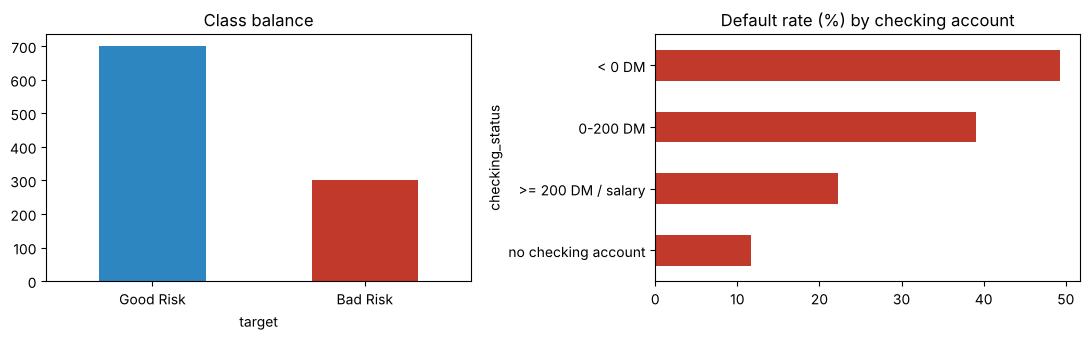

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
y.map({0: "Good Risk", 1: "Bad Risk"}).value_counts().plot.bar(ax=ax[0], color=["#2e86c1", "#c0392b"], rot=0, title="Class balance")
(pd.crosstab(X["checking_status"], y, normalize="index")[1] * 100).sort_values().plot.barh(ax=ax[1], color="#c0392b", title="Default rate (%) by checking account")
plt.tight_layout(); plt.show()

A model that approves everyone is already 70% accurate, which is why the thesis judges the models on recall, F1, AUC and misclassification cost rather than accuracy alone.

## 2. Inside a saved model
Each saved model is a single pipeline: **encode and scale → SMOTE (training only) → classifier**. SMOTE is skipped automatically when the pipeline predicts, so new applicants are never resampled.

In [4]:
models[cm.LR]

,steps,"[('pre', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](20,)","['checking_status','duration','credit_history',...,'num_dependents', 'telephone','foreign_worker']"
n_features_in_,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [5]:
for n in models: print(f"{n}: {card['params'][n]}  (CV F1 {card['cv_f1'][n]})")
print("Tree size:", card["tree_size"])

Logistic Regression: {'C': 0.1}  (CV F1 0.5988)
Decision Tree: {'ccp_alpha': 0.005, 'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2}  (CV F1 0.5736)
Tree size: {'depth': 6, 'leaves': 15}


## 3. Reproducing the thesis results
The same stratified 80/20 split with seed 42 recreates the 200 test applicants that neither model saw during training. The numbers below should match Table 5.4 of the thesis exactly.

In [6]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, stratify=y, random_state=cm.SEED)
pd.DataFrame({n: {k: v for k, v in card["test_default_threshold"][n].items() if not k.startswith("confusion")} for n in models}).T

,accuracy,precision,recall,specificity,f1,auc,ap,cost
Logistic Regression,0.755,0.5679,0.7667,0.7500,0.6525,0.8093,0.6642,105.0
Decision Tree,0.655,0.4384,0.5333,0.7071,0.4812,0.6852,0.4371,181.0


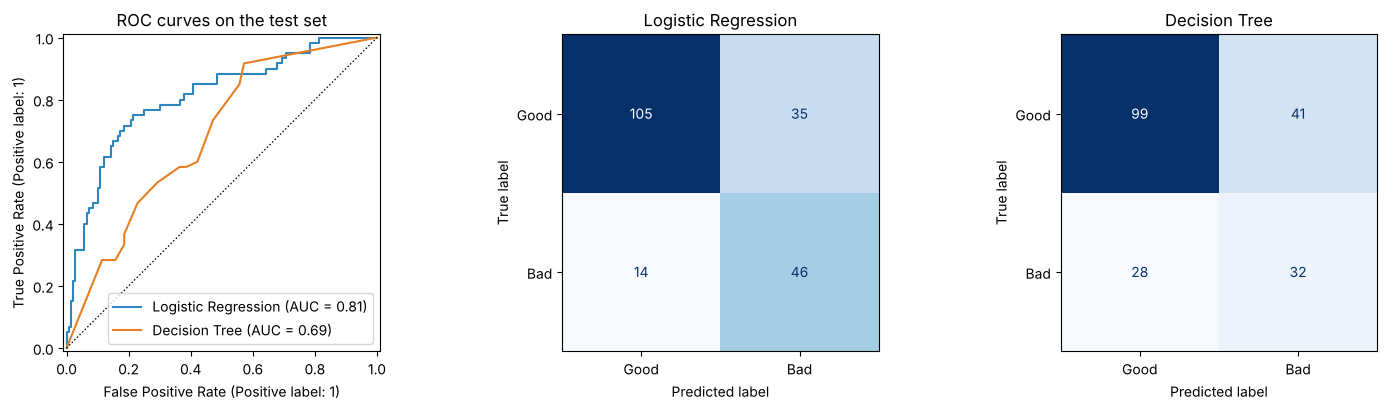

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for n, c in zip(models, ["#2e86c1", "#e67e22"]):
    RocCurveDisplay.from_estimator(models[n], Xte, yte, ax=ax[0], name=n, curve_kwargs={"color": c})
ax[0].plot([0, 1], [0, 1], "k:", lw=1); ax[0].set_title("ROC curves on the test set")
for a, n in zip(ax[1:], models):
    ConfusionMatrixDisplay.from_estimator(models[n], Xte, yte, display_labels=["Good", "Bad"], ax=a, colorbar=False, cmap="Blues")
    a.set_title(n)
plt.tight_layout(); plt.show()

Logistic Regression catches 46 of the 60 defaulters (recall 0.767) against the tree's 32 (0.533), with an AUC of 0.809 against 0.685. Chapter 5 shows that this gap survives repeated cross-validation, corrected significance tests and sixteen robustness variants.

## 4. Scoring one applicant, and explaining the decision
Ten real test-set applicants are stored in `examples/sample_applicants.csv` together with what actually happened to them.

In [8]:
samples = pd.read_csv(cm.HERE / "examples" / "sample_applicants.csv").set_index("applicant_id")
samples[["checking_status", "duration", "credit_amount", "purpose", "savings", "age", "actual_outcome"]]

,checking_status,duration,credit_amount,purpose,savings,age,actual_outcome
applicant_id,,,,,,,
T033,0-200 DM,48,15672,business,< 100 DM,23,Bad Risk
T042,0-200 DM,24,4351,furniture/equipment,unknown/none,48,Good Risk
T065,>= 200 DM / salary,12,1330,car (new),< 100 DM,26,Good Risk
T068,0-200 DM,48,18424,others,< 100 DM,32,Bad Risk
T103,no checking account,18,3422,furniture/equipment,< 100 DM,47,Good Risk
T115,< 0 DM,12,1108,repairs,< 100 DM,28,Bad Risk
T156,< 0 DM,30,3857,car (used),< 100 DM,40,Good Risk
T170,0-200 DM,36,12389,car (new),unknown/none,37,Bad Risk
T173,no checking account,12,2096,education,< 100 DM,49,Good Risk


In [9]:
applicant = samples.loc["T115"].drop("actual_outcome").to_dict()
pd.DataFrame(cm.score(models, card, applicant)).T

,p_bad,decision_default,threshold_cost,decision_cost
Logistic Regression,0.501702,REFER / DECLINE,0.29,REFER / DECLINE
Decision Tree,0.155844,APPROVE,0.09,REFER / DECLINE


**Logistic Regression explanation.** The log-odds of default are the intercept plus one contribution per attribute (coefficient × encoded value). The contributions add up *exactly* to the model's output, so this explanation is the model itself, not an approximation.

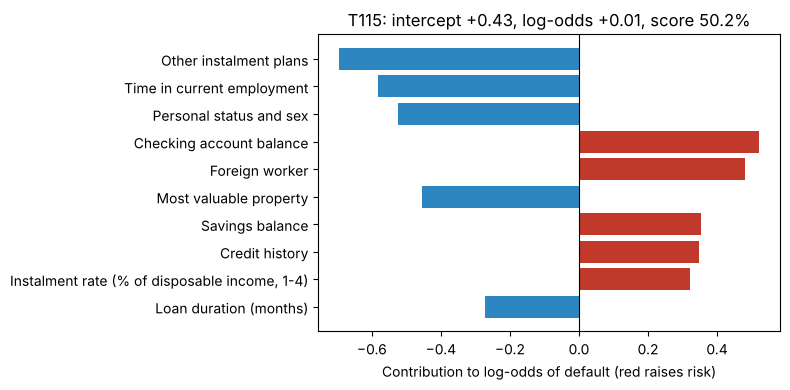

In [10]:
table, intercept, logit = cm.explain_lr(models[cm.LR], applicant)
t = table.head(10).iloc[::-1]
plt.figure(figsize=(8, 4))
plt.barh(t["attribute"].map(cm.PRETTY), t["contribution"], color=np.where(t["contribution"] > 0, "#c0392b", "#2e86c1"))
plt.axvline(0, color="k", lw=0.8); plt.xlabel("Contribution to log-odds of default (red raises risk)")
plt.title(f"T115: intercept {intercept:+.2f}, log-odds {logit:+.2f}, score {1/(1+np.exp(-logit)):.1%}")
plt.tight_layout(); plt.show()

**Decision Tree explanation.** The tree's reasoning is the chain of yes/no questions that led this applicant to a leaf.

In [11]:
rules, leaf = cm.explain_dt(models[cm.DT], applicant)
for i, r in enumerate(rules, 1): print(f"{i}. {r}")
print(f"-> leaf {leaf['node']} with {leaf['training_records']} training records, {leaf['p_bad']:.0%} Bad Risk")

1. Checking account balance is not 'no checking account'   (applicant: < 0 DM)
2. Loan duration (months) <= 12.1   (applicant: 12)
3. Most valuable property is 'real estate'   (applicant: real estate)
-> leaf 10 with 77 training records, 16% Bad Risk


Applicant T115 really did default. Logistic Regression flags them (score about 50%), mainly because of the overdrawn checking account. The tree sends them to a leaf dominated by good payers because the loan is short and they own real estate, and approves them. This is a single case, but it illustrates the pattern in Chapter 5: the tree's hard splits can let a risky applicant through when one strong signal is outweighed by the path it happens to follow.

## 5. What if?
Change one attribute and watch both models respond. Here the same applicant has no checking account instead of an overdrawn one.

In [12]:
what_if = dict(applicant, checking_status="no checking account")
pd.DataFrame({"original": {n: r["p_bad"] for n, r in cm.score(models, card, applicant).items()},
              "no checking account": {n: r["p_bad"] for n, r in cm.score(models, card, what_if).items()}}).style.format("{:.1%}")

,original,no checking account
Logistic Regression,50.2%,18.3%
Decision Tree,15.6%,9.7%


## 6. Scoring a batch
A lender would score many applications at once. The command-line tool does the same with `python predict.py --batch file.csv`.

In [13]:
batch = samples.copy()
for n, m in models.items():
    batch[n] = m.predict_proba(cm.to_frame(samples.drop(columns="actual_outcome")))[:, 1].round(3)
batch["LR decision (t=%.2f)" % card["thresholds"][cm.LR]] = np.where(batch[cm.LR] >= card["thresholds"][cm.LR], "REFER / DECLINE", "APPROVE")
batch["DT decision (t=0.50)"] = np.where(batch[cm.DT] >= 0.5, "REFER / DECLINE", "APPROVE")
batch[["actual_outcome", cm.LR, cm.DT, batch.columns[-2], batch.columns[-1]]]

,actual_outcome,Logistic Regression,Decision Tree,LR decision (t=0.29),DT decision (t=0.50)
applicant_id,,,,,
T033,Bad Risk,0.849,0.653,REFER / DECLINE,REFER / DECLINE
T042,Good Risk,0.280,0.316,APPROVE,APPROVE
T065,Good Risk,0.556,0.156,REFER / DECLINE,APPROVE
T068,Bad Risk,0.905,0.580,REFER / DECLINE,REFER / DECLINE
T103,Good Risk,0.573,0.352,REFER / DECLINE,APPROVE
T115,Bad Risk,0.502,0.156,REFER / DECLINE,APPROVE
T156,Good Risk,0.696,0.580,REFER / DECLINE,REFER / DECLINE
T170,Bad Risk,0.622,0.250,REFER / DECLINE,APPROVE
T173,Good Risk,0.065,0.097,APPROVE,APPROVE


## 7. The tree itself
The full tuned tree (depth 6, 15 leaves) can be drawn and read from top to bottom. Splits on dummy columns at values other than 0.5 are a side effect of SMOTE creating fractional category values, a point examined in Section 5.8 and Chapter 6 of the thesis.

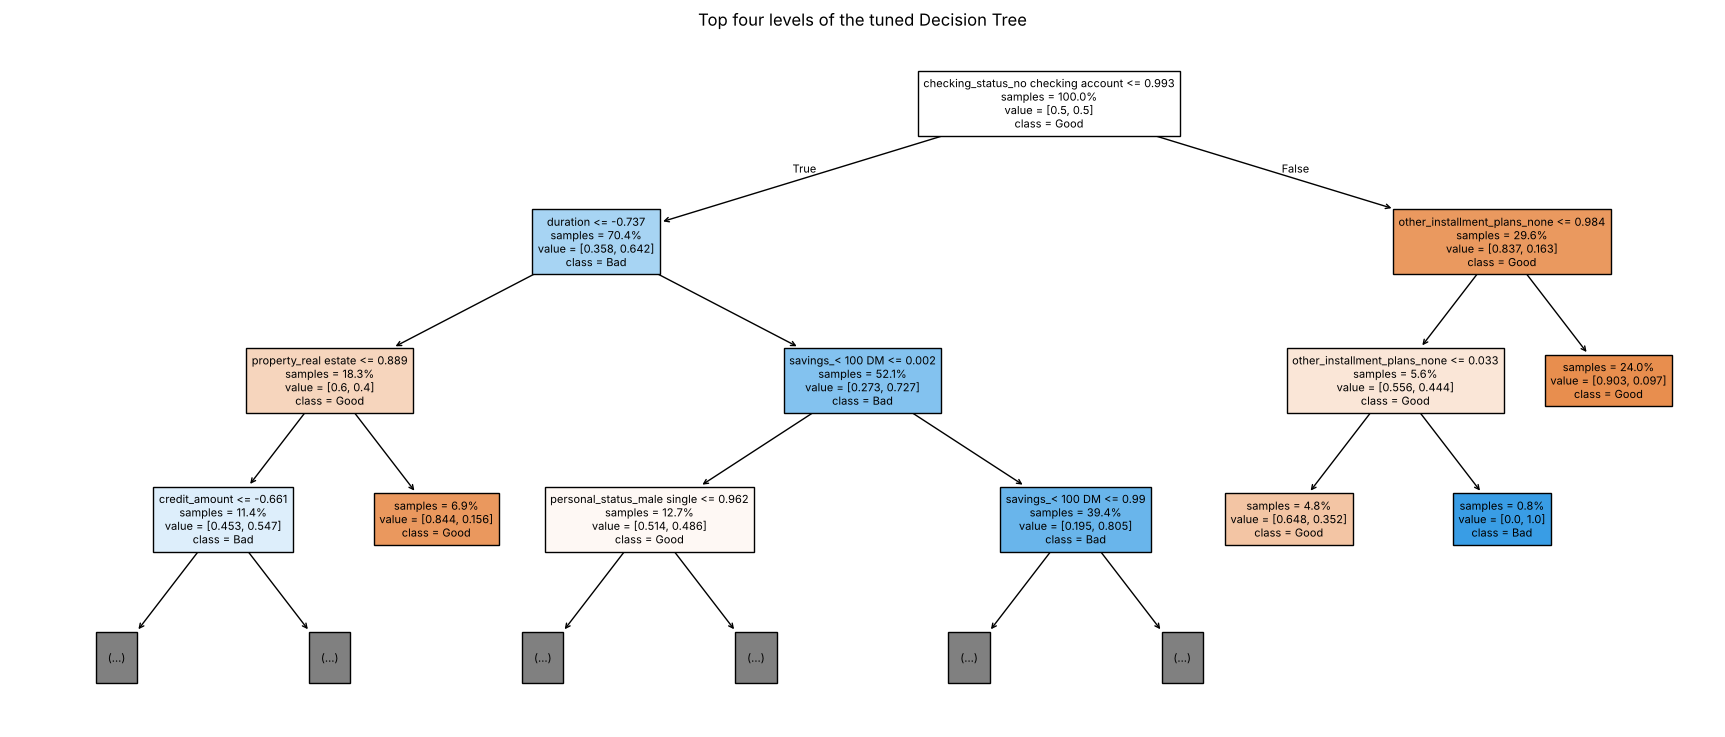

In [14]:
dt = models[cm.DT]
names = [f.split("__", 1)[1] for f in dt.named_steps["pre"].get_feature_names_out()]
plt.figure(figsize=(22, 9))
plot_tree(dt.named_steps["clf"], feature_names=names, class_names=["Good", "Bad"], filled=True, max_depth=3, fontsize=8, impurity=False, proportion=True)
plt.title("Top four levels of the tuned Decision Tree"); plt.show()

## 8. Every number in the thesis
`verify_thesis.py` re-scores the saved models on the test set, recomputes the SMOTE finding of Section 5.8 from scratch and compares every other figure in Chapters 5 and 6 and Appendix A with the outputs of the experiment scripts. The full table is written to `thesis_check_report.md`, and the *Verification* tab of the web app shows the same report.

In [15]:
import subprocess, sys
run = subprocess.run([sys.executable, "verify_thesis.py"], capture_output=True, text=True)
print(run.stdout)
report = pd.read_csv("thesis_check_report.csv")
report["section"] = report["where"].str.replace(" (live)", "").str.replace(" (saved model, live)", "")
report.groupby("section", sort=False)["passed"].agg(checks="size", passed="sum")

188/188 thesis claims reproduced. Full table in thesis_check_report.md



,checks,passed
section,,
Table 5.4,23,23
Table 5.6,3,3
Section 5.6.1,4,4
Section 5.4,4,4
Section 5.5,3,3
Section 5.2,4,4
Section 5.3,5,5
Section 5.8,14,14
Table A.2,9,9


## Limitations to keep in mind
* The scores come from models trained on SMOTE-balanced data, so they rank applicants well but overstate the chance of default compared with the 30% base rate. They are risk scores, not calibrated probabilities.
* The data describe German borrowers in the 1970s. The models demonstrate a method; they are not a lending tool for Namibia.
* Attributes such as sex, marital status and foreign-worker status are in the data, and Chapter 4 explains why they would need to be removed or tested for fairness before any real use.